# Hardware results plots (USRP + phone)

All eight hardware configurations can be compared with each other, because every one used the **same phone** as the UE.
This notebook makes:

1. **Control plane:** a summary table (no figure)
2. **User plane:** a four-panel figure (DL throughput, UL throughput, RTT, jitter) plus a radio-quality table
3. **Resource usage:** a combined figure (saturation on top, fixed load underneath) in the same layout as the simulation one

In every figure the configurations are grouped by RAN (OCUDU on the left, OAI on the right).
Colour = core network and white hatching = split, exactly as in the simulation figures.

**Before running:** put this notebook next to your `5g_open_source_benchmarking` folder,
or change `RESULTS_DIR` in the first code cell. Run the cells from top to bottom.

In [1]:
import re
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory
from scipy import stats

%config InlineBackend.figure_format = "retina"   # sharper preview inside Jupyter

# ---- Settings you may need to change ----
RESULTS_DIR = Path("5g_open_source_benchmarking/results")
OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# ---- Colours (same options as the simulation notebooks) ----
PALETTES = {
    "blue_coral":       {"open5gs": "#1F6FB2", "free5gc": "#EE6B5E"},  # current choice
    "navy_coral":       {"open5gs": "#1F3A5F", "free5gc": "#EE6B5E"},  # better for black-and-white printing
    "blue_vermillion":  {"open5gs": "#0072B2", "free5gc": "#D55E00"},  # colour-blind safe
    "teal_coral":       {"open5gs": "#00798C", "free5gc": "#D1495B"},
    "navy_gold":        {"open5gs": "#1F3A5F", "free5gc": "#E3A72F"},  # most formal, prints well
    "purple_green":     {"open5gs": "#5E4FA2", "free5gc": "#3AA17E"},
}
PALETTE = "blue_coral"          # keep this the same as in the simulation notebooks
CORE_COLOURS = PALETTES[PALETTE]
CORE_NAMES = {"open5gs": "Open5GS", "free5gc": "free5GC"}
RAN_NAMES = {"ocudu": "OCUDU", "oai": "OAI"}
OUTLINE = "#222222"

# Resource figure: colours show components (as in the simulation resource figures)
COMPONENT_COLOURS = {"gNB / DU": "#1F6FB2", "CU": "#7FB3E0", "5GC": "#EE6B5E"}
HOST_COLOURS = {"RAN host": "#1F6FB2", "Core host": "#EE6B5E"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## Configurations

Each configuration is: (ID, core, RAN, architecture, results folder, run folder name).
The `ran` column in the hardware CSVs is `ocudu` or `oai` for both architectures, so the architecture is taken from the folder.

The x positions leave a gap between the OCUDU and OAI groups.

In [2]:
MONO = "5g_phone_mono_results"
SPLIT = "5g_split_hardware"

CONFIGS = [
    ("H1", "open5gs", "ocudu", "mono",  MONO,  "open5gs_ocudu_phone"),
    ("H2", "free5gc", "ocudu", "mono",  MONO,  "free5gc_ocudu_phone"),
    ("H3", "open5gs", "ocudu", "split", SPLIT, "open5gs_ocudu_split_phone"),
    ("H4", "free5gc", "ocudu", "split", SPLIT, "free5gc_ocudu_split_phone"),
    ("H5", "open5gs", "oai",   "mono",  MONO,  "open5gs_oai_phone"),
    ("H6", "free5gc", "oai",   "mono",  MONO,  "free5gc_oai_phone"),
    ("H7", "open5gs", "oai",   "split", SPLIT, "open5gs_oai_split_phone"),
    ("H8", "free5gc", "oai",   "split", SPLIT, "free5gc_oai_split_phone"),
]
X_POS = [0, 1, 2, 3, 5, 6, 7, 8]          # gap at 4 separates the two RAN groups

## Loading the data and shared drawing helpers

- `runs` holds every run from both hardware CSVs, with an extra `arch` column (mono / split).
- `rows_for` picks the three runs of one configuration.
- `load_pings` reads every individual ping (core host → phone) from the raw `ping_phone.txt` files.
- `read_power_file` / `load_power` / `load_fixed_power` recompute average power from the raw RAPL files (decimals instead of whole watts).
- `format_axis` adds the configuration labels and the OCUDU / OAI group labels underneath.

In [3]:
def load_runs():
    frames = []
    for folder, arch in ((MONO, "mono"), (SPLIT, "split")):
        df = pd.read_csv(RESULTS_DIR / folder / "all_results.csv")
        df["arch"] = arch
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


runs = load_runs()


def rows_for(core, ran, arch):
    return runs[(runs.core == core) & (runs.ran == ran) & (runs.arch == arch)]


def col(rows, *names):
    """Numeric values of the first column that exists and has data (gnb_* for mono, du_* for split)."""
    for name in names:
        if name in rows:
            values = pd.to_numeric(rows[name], errors="coerce").dropna()
            if len(values):
                return values.values
    return np.array([0.0])


def ci95(values):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return 0.0
    return stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))


def load_pings(folder, run_folder):
    times = []
    for path in sorted(glob.glob(str(RESULTS_DIR / folder / "round*" / run_folder / "raw" / "ping_phone.txt"))):
        times += [float(t) for t in re.findall(r"time=([\d.]+)", Path(path).read_text(errors="ignore"))]
    return np.array(times)


def read_power_file(path):
    text = Path(path).read_text(errors="ignore")
    joules = float(re.search(r"Total energy\s*\(J\)\s*:\s*([\d.]+)", text).group(1))
    seconds = float(re.search(r"Duration\s*\(s\)\s*:\s*([\d.]+)", text).group(1))
    return joules / seconds


def load_power(folder, run_folder):
    """Saturation-phase average power per host, one row per round."""
    rows = []
    for rnd in sorted((RESULTS_DIR / folder).glob("round*")):
        raw = rnd / run_folder / "raw"
        if (raw / "power_ran.txt").exists():
            rows.append({"RAN host": read_power_file(raw / "power_ran.txt"),
                         "Core host": read_power_file(raw / "power_core.txt")})
    return pd.DataFrame(rows)


def load_fixed_power(folder, run_folder):
    """Fixed-load average power per host (total energy / window length), one row per round."""
    rows = []
    for rnd in sorted((RESULTS_DIR / folder).glob("round*")):
        f = rnd / run_folder / "raw" / "fixed_load" / "power.txt"
        if f.exists():
            vals = dict(re.findall(r"(\w+)=([\d.]+)", f.read_text(errors="ignore")))
            dur = float(vals["duration_s"])
            rows.append({"RAN host": float(vals["ran_joules"]) / dur,
                         "Core host": float(vals["core_joules"]) / dur})
    return pd.DataFrame(rows)


def short_label(core, arch):
    return f"{CORE_NAMES[core]}\n{'Split' if arch == 'split' else 'Mono'}"


def long_label(core, ran, arch):
    return f"{RAN_NAMES[ran]} – {CORE_NAMES[core]} – {'Split (CU/DU)' if arch == 'split' else 'Monolithic'}"


def styled_bar(ax, x, height, core, arch, width=0.7):
    split = arch == "split"
    ax.bar(x, height, width, color=CORE_COLOURS[core], hatch="///" if split else None,
           edgecolor="white" if split else CORE_COLOURS[core], linewidth=0)
    ax.bar(x, height, width, fill=False, edgecolor=OUTLINE, linewidth=1)


def format_axis(ax, ylabel, title=None):
    """Configuration labels, OCUDU / OAI group labels underneath, and a divider between the groups."""
    ax.set_xticks(X_POS)
    ax.set_xticklabels([short_label(c, a) for _, c, _, a, _, _ in CONFIGS], fontsize=8)
    ax.set_xlim(-0.6, 8.6)
    ax.axvline(4, color="#999999", linewidth=0.8, linestyle="--")
    trans = blended_transform_factory(ax.transData, ax.transAxes)
    for centre, name in ((1.5, "OCUDU"), (6.5, "OAI")):
        ax.text(centre, -0.2, name, transform=trans, ha="center", va="top", fontsize=10, fontweight="bold")
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)


def save(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")
    print(f"Saved {name}.png and .pdf in {OUTPUT_DIR}")

## 1. Control plane: summary table

**Use the median, not the mean, for the hardware control plane.** Several runs had PDU session setup times of
2 to 25 **seconds**, against roughly 65–220 ms in the other runs. A mean would be dominated by those few runs;
the median shows the typical value and the min–max shows the outliers honestly.

Before explaining these outliers in the report, check the AMF/SMF logs of those runs for the gap between
*Registration Complete* and the phone's *PDU Session Establishment Request*. A long gap means the phone waited before asking
for a data session; a short gap means the delay was inside the core network.

The table is printed, saved as CSV, and printed again as LaTeX for your report.

In [4]:
cp_rows = []
for cid, core, ran, arch, folder, run in CONFIGS:
    rows = rows_for(core, ran, arch)
    reg, pdu = col(rows, "reg_ms"), col(rows, "pdu_setup_ms")
    cp_rows.append({
        "ID": cid,
        "RAN": RAN_NAMES[ran],
        "Core": CORE_NAMES[core],
        "Architecture": "Split (CU/DU)" if arch == "split" else "Monolithic",
        "Attach success": f"{(rows['status'] == 'PASS').sum()}/{len(rows)}",
        "Registration median (ms)": int(np.median(reg)),
        "Registration min–max (ms)": f"{reg.min():.0f}–{reg.max():.0f}",
        "PDU setup median (ms)": int(np.median(pdu)),
        "PDU setup min–max (ms)": f"{pdu.min():.0f}–{pdu.max():.0f}",
    })
control_plane = pd.DataFrame(cp_rows).set_index("ID")
display(control_plane)

control_plane.to_csv(OUTPUT_DIR / "hw_control_plane.csv")
print(control_plane.to_latex())

,RAN,Core,Architecture,Attach success,Registration median (ms),Registration min–max (ms),PDU setup median (ms),PDU setup min–max (ms)
ID,,,,,,,,
H1,OCUDU,Open5GS,Monolithic,3/3,296,292–316,112,107–157
H2,OCUDU,free5GC,Monolithic,3/3,394,391–419,14896,2127–19589
H3,OCUDU,Open5GS,Split (CU/DU),3/3,391,375–418,88,65–93
H4,OCUDU,free5GC,Split (CU/DU),3/3,473,473–497,107,88–122
H5,OAI,Open5GS,Monolithic,3/3,174,174–189,205,184–209
H6,OAI,free5GC,Monolithic,3/3,253,209–255,2415,202–25249
H7,OAI,Open5GS,Split (CU/DU),3/3,210,209–213,219,190–10213
H8,OAI,free5GC,Split (CU/DU),3/3,243,204–243,205,204–218


\begin{tabular}{lllllrlrl}
\toprule
 & RAN & Core & Architecture & Attach success & Registration median (ms) & Registration min–max (ms) & PDU setup median (ms) & PDU setup min–max (ms) \\
ID &  &  &  &  &  &  &  &  \\
\midrule
H1 & OCUDU & Open5GS & Monolithic & 3/3 & 296 & 292–316 & 112 & 107–157 \\
H2 & OCUDU & free5GC & Monolithic & 3/3 & 394 & 391–419 & 14896 & 2127–19589 \\
H3 & OCUDU & Open5GS & Split (CU/DU) & 3/3 & 391 & 375–418 & 88 & 65–93 \\
H4 & OCUDU & free5GC & Split (CU/DU) & 3/3 & 473 & 473–497 & 107 & 88–122 \\
H5 & OAI & Open5GS & Monolithic & 3/3 & 174 & 174–189 & 205 & 184–209 \\
H6 & OAI & free5GC & Monolithic & 3/3 & 253 & 209–255 & 2415 & 202–25249 \\
H7 & OAI & Open5GS & Split (CU/DU) & 3/3 & 210 & 209–213 & 219 & 190–10213 \\
H8 & OAI & free5GC & Split (CU/DU) & 3/3 & 243 & 204–243 & 205 & 204–218 \\
\bottomrule
\end{tabular}



## 2. User plane

Four panels, each with the eight configurations grouped by RAN:

- **(a) Downlink and (b) uplink TCP throughput:** bar = mean of 3 runs, error bar = 95% confidence interval.
  Downlink and uplink are separate panels because eight configurations × two directions in one panel is too crowded.
- **(c) RTT:** box plot of all pings from the **core host to the phone** (no internet path, unlike the simulations).
  Box = middle 50% of pings, line = median, whiskers = fastest and slowest ping.
- **(d) Jitter:** bar = mean of 3 runs, dots = individual runs.

Saved hw_user_plane.png and .pdf in figures


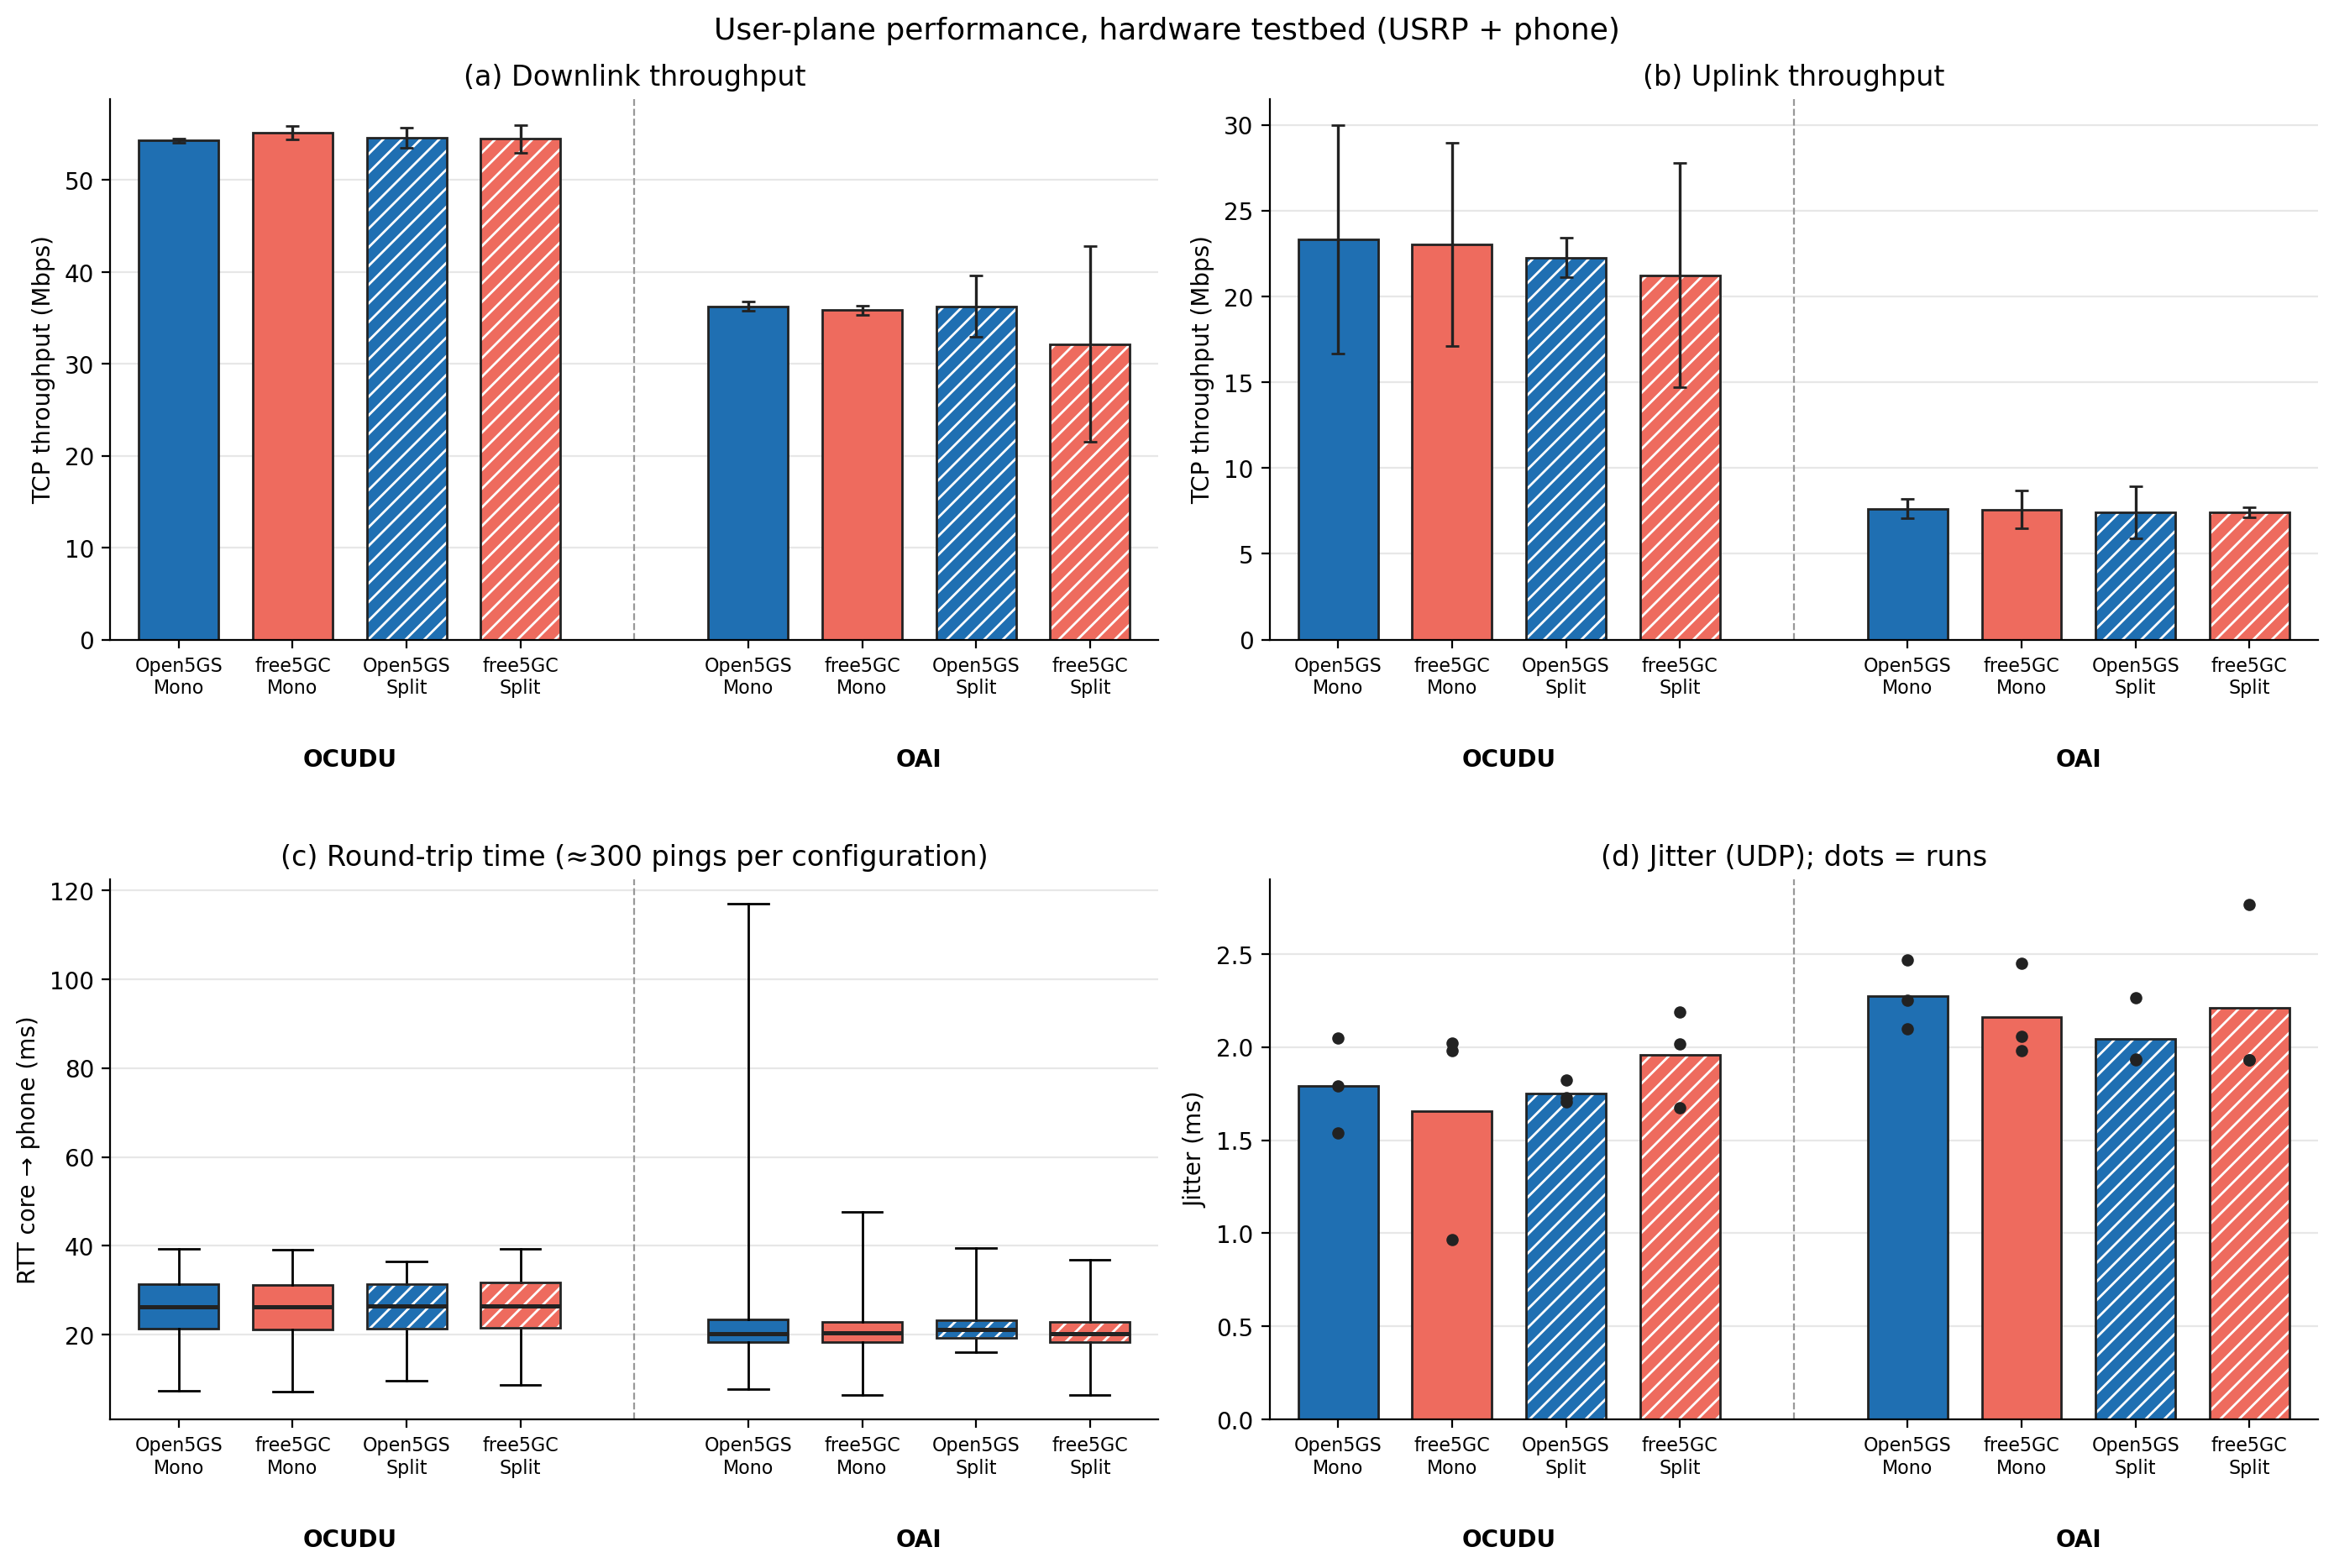

OCUDU – Open5GS – Monolithic: mean 26.2 ms, median 26.3 ms, middle 50% 21.4-31.4 ms, range 7.3-39.4 ms
OCUDU – free5GC – Monolithic: mean 26.0 ms, median 26.3 ms, middle 50% 21.2-31.3 ms, range 7.3-39.2 ms
OCUDU – Open5GS – Split (CU/DU): mean 26.3 ms, median 26.5 ms, middle 50% 21.5-31.4 ms, range 9.7-36.5 ms
OCUDU – free5GC – Split (CU/DU): mean 26.6 ms, median 26.4 ms, middle 50% 21.6-31.7 ms, range 8.8-39.3 ms
OAI – Open5GS – Monolithic: mean 21.5 ms, median 20.3 ms, middle 50% 18.3-23.4 ms, range 7.8-117.0 ms
OAI – free5GC – Monolithic: mean 21.0 ms, median 20.4 ms, middle 50% 18.3-22.9 ms, range 6.5-47.7 ms
OAI – Open5GS – Split (CU/DU): mean 21.6 ms, median 21.1 ms, middle 50% 19.3-23.3 ms, range 16.1-39.5 ms
OAI – free5GC – Split (CU/DU): mean 20.7 ms, median 20.3 ms, middle 50% 18.3-22.9 ms, range 6.5-36.9 ms


In [5]:
def plot_user_plane_hw(save_fig=True):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
    ax_dl, ax_ul, ax_rtt, ax_jit = axes.flat

    for x, (cid, core, ran, arch, folder, run) in zip(X_POS, CONFIGS):
        rows = rows_for(core, ran, arch)
        for ax, metric in ((ax_dl, "tcp_dl_mbps"), (ax_ul, "tcp_ul_mbps")):
            v = col(rows, metric)
            styled_bar(ax, x, v.mean(), core, arch)
            ax.errorbar(x, v.mean(), yerr=ci95(v), color=OUTLINE, capsize=3, linewidth=1.2)
        v = col(rows, "jitter_ms")
        styled_bar(ax_jit, x, v.mean(), core, arch)
        ax_jit.scatter([x] * len(v), v, color=OUTLINE, s=18, zorder=4)

    pings = [load_pings(folder, run) for _, _, _, _, folder, run in CONFIGS]
    box = ax_rtt.boxplot(pings, positions=X_POS, widths=0.7, patch_artist=True, whis=(0, 100),
                         showfliers=False, medianprops=dict(color=OUTLINE, linewidth=1.8))
    for patch, (_, core, _, arch, _, _) in zip(box["boxes"], CONFIGS):
        patch.set_facecolor(CORE_COLOURS[core])
        patch.set_edgecolor(OUTLINE)
        if arch == "split":
            patch.set_hatch("///")
            patch.set_edgecolor("white")
            (x0, y0), (x1, y1) = patch.get_path().vertices.min(0), patch.get_path().vertices.max(0)
            ax_rtt.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                           edgecolor=OUTLINE, linewidth=1, zorder=3))

    format_axis(ax_dl, "TCP throughput (Mbps)", "(a) Downlink throughput")
    format_axis(ax_ul, "TCP throughput (Mbps)", "(b) Uplink throughput")
    format_axis(ax_rtt, "RTT core → phone (ms)", "(c) Round-trip time (≈300 pings per configuration)")
    format_axis(ax_jit, "Jitter (ms)", "(d) Jitter (UDP); dots = runs")

    fig.suptitle("User-plane performance, hardware testbed (USRP + phone)", fontsize=13)
    fig.tight_layout(h_pad=3)
    if save_fig:
        save(fig, "hw_user_plane")
    plt.show()

    for (cid, core, ran, arch, _, _), p in zip(CONFIGS, pings):
        print(f"{long_label(core, ran, arch)}: mean {p.mean():.1f} ms, median {np.median(p):.1f} ms, "
              f"middle 50% {np.percentile(p, 25):.1f}-{np.percentile(p, 75):.1f} ms, range {p.min():.1f}-{p.max():.1f} ms")


plot_user_plane_hw()

### Radio-quality table (supports the user-plane results)

The hardware runs also recorded radio metrics. They explain *why* throughput differs between the RANs,
so this table belongs next to the user-plane figure: e.g. a lower MCS (modulation and coding scheme) means fewer bits per transmission.
DL RSRP and DL SINR were only reported by OAI, so they show as blank for OCUDU.

In [6]:
radio_cols = {
    "cqi": "CQI", "dl_mcs": "DL MCS", "dl_bler_pct": "DL BLER (%)",
    "ul_mcs": "UL MCS", "ul_bler_pct": "UL BLER (%)", "ul_snr_db": "UL SNR (dB)",
    "dl_rsrp_dbm": "DL RSRP (dBm)", "dl_sinr_db": "DL SINR (dB)",
}
radio_rows = []
for cid, core, ran, arch, _, _ in CONFIGS:
    rows = rows_for(core, ran, arch)
    entry = {"ID": cid, "Configuration": long_label(core, ran, arch)}
    for column, name in radio_cols.items():
        v = pd.to_numeric(rows[column], errors="coerce").dropna()
        entry[name] = round(v.mean(), 1) if len(v) else np.nan
    radio_rows.append(entry)
radio = pd.DataFrame(radio_rows).set_index("ID")
display(radio)

radio.to_csv(OUTPUT_DIR / "hw_radio_quality.csv")
print(radio.to_latex(float_format="%.1f", na_rep="–"))

,Configuration,CQI,DL MCS,DL BLER (%),UL MCS,UL BLER (%),UL SNR (dB),DL RSRP (dBm),DL SINR (dB)
ID,,,,,,,,,
H1,OCUDU – Open5GS – Monolithic,15.0,25.1,0.2,26.2,4.2,31.1,NaN,NaN
H2,OCUDU – free5GC – Monolithic,15.0,25.8,0.2,26.5,4.2,31.1,NaN,NaN
H3,OCUDU – Open5GS – Split (CU/DU),15.0,25.2,0.3,26.4,6.3,30.7,NaN,NaN
H4,OCUDU – free5GC – Split (CU/DU),15.0,25.1,0.3,26.2,8.6,30.9,NaN,NaN
H5,OAI – Open5GS – Monolithic,14.5,12.5,6.2,7.7,6.1,15.4,-87.9,23.5
H6,OAI – free5GC – Monolithic,14.6,12.6,6.0,6.7,5.9,15.3,-87.8,23.5
H7,OAI – Open5GS – Split (CU/DU),14.5,11.6,6.0,6.0,6.2,15.4,-87.8,23.5
H8,OAI – free5GC – Split (CU/DU),14.7,11.6,5.9,6.2,6.4,15.5,-87.7,23.5


\begin{tabular}{llrrrrrrrr}
\toprule
 & Configuration & CQI & DL MCS & DL BLER (%) & UL MCS & UL BLER (%) & UL SNR (dB) & DL RSRP (dBm) & DL SINR (dB) \\
ID &  &  &  &  &  &  &  &  &  \\
\midrule
H1 & OCUDU – Open5GS – Monolithic & 15.0 & 25.1 & 0.2 & 26.2 & 4.2 & 31.1 & – & – \\
H2 & OCUDU – free5GC – Monolithic & 15.0 & 25.8 & 0.2 & 26.5 & 4.2 & 31.1 & – & – \\
H3 & OCUDU – Open5GS – Split (CU/DU) & 15.0 & 25.2 & 0.3 & 26.4 & 6.3 & 30.7 & – & – \\
H4 & OCUDU – free5GC – Split (CU/DU) & 15.0 & 25.1 & 0.3 & 26.2 & 8.6 & 30.9 & – & – \\
H5 & OAI – Open5GS – Monolithic & 14.5 & 12.5 & 6.2 & 7.7 & 6.1 & 15.4 & -87.9 & 23.5 \\
H6 & OAI – free5GC – Monolithic & 14.6 & 12.6 & 6.0 & 6.7 & 5.9 & 15.3 & -87.8 & 23.5 \\
H7 & OAI – Open5GS – Split (CU/DU) & 14.5 & 11.6 & 6.0 & 6.0 & 6.2 & 15.4 & -87.8 & 23.5 \\
H8 & OAI – free5GC – Split (CU/DU) & 14.7 & 11.6 & 5.9 & 6.2 & 6.4 & 15.5 & -87.7 & 23.5 \\
\bottomrule
\end{tabular}



## 3. Resource usage (saturation on top, fixed load underneath)

Same layout as the combined simulation figure: columns are CPU per component, memory per component and average power per host;
each column uses the same y-axis scale in both rows. There is no UE component here, because the phone is a separate device.

The fixed-load row matters more in hardware than in simulation: at saturation the OCUDU and OAI configurations carried
different amounts of traffic (about 55 vs 36 Mbps downlink), so **only the fixed-load row compares the RANs at identical traffic.**

Saved hw_resources_combined.png and .pdf in figures


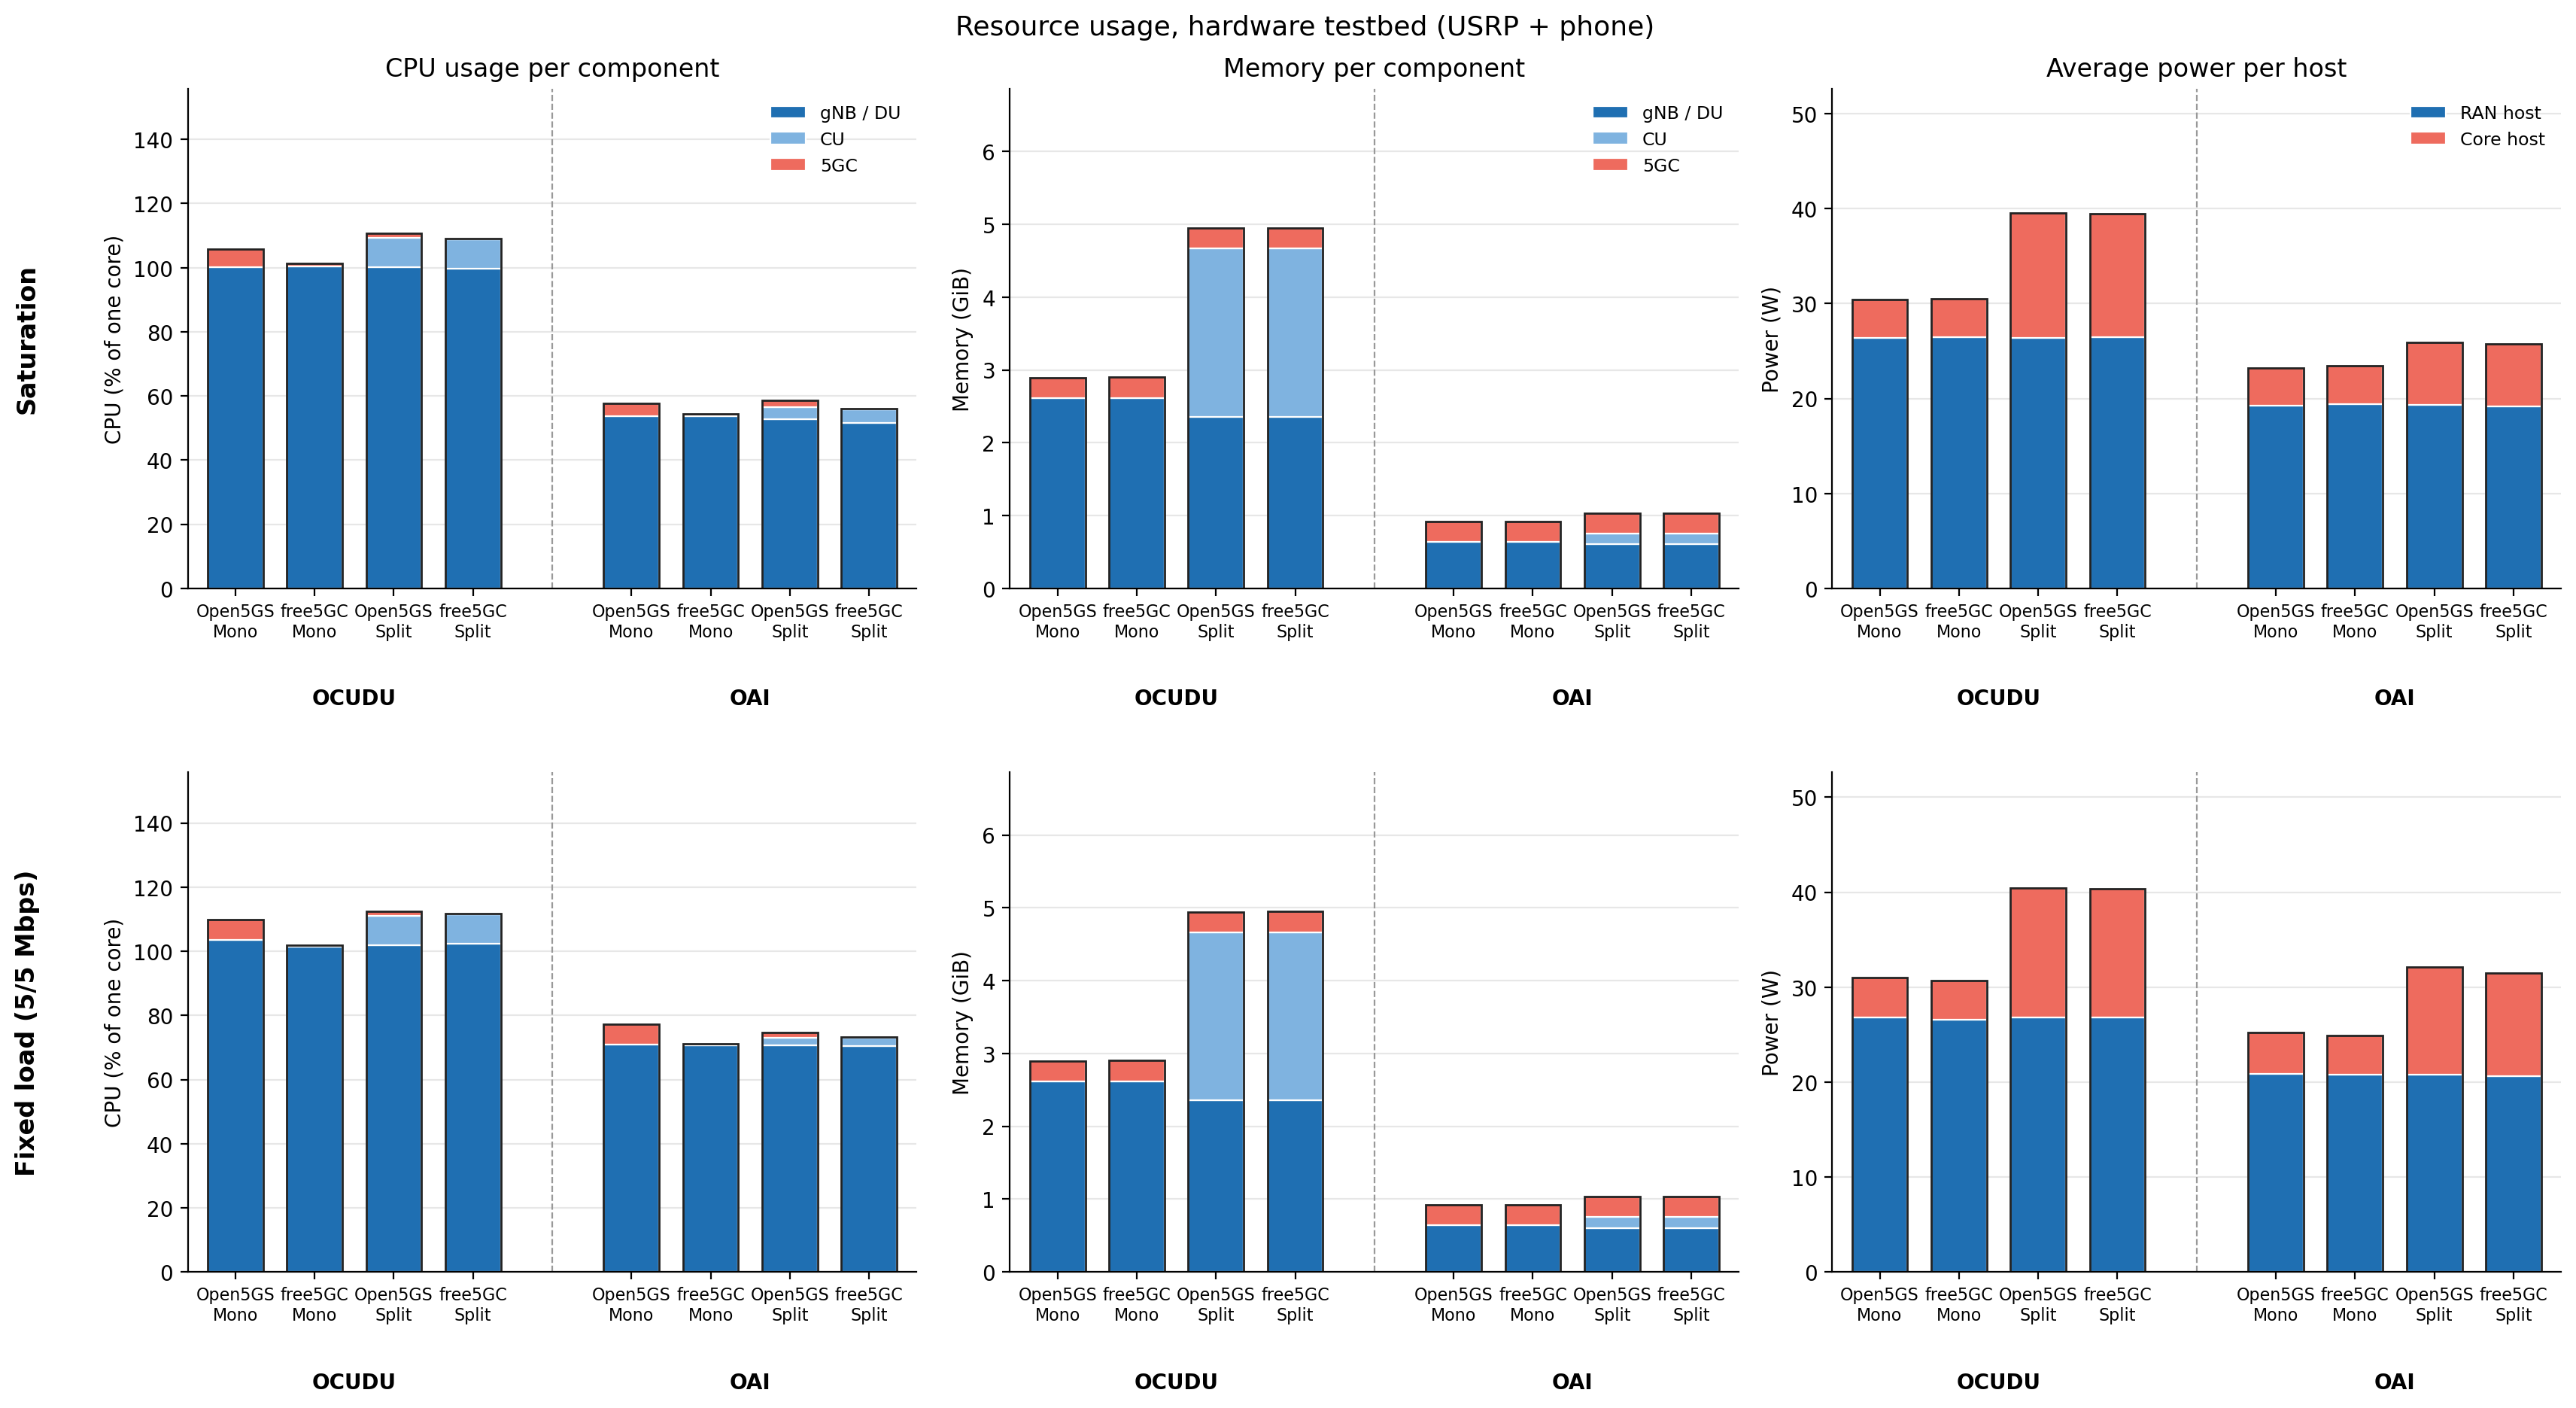

,Configuration,Fixed load valid,"Total CPU, sat. (%)","Total CPU, fixed (%)","Memory, sat. (GiB)","Memory, fixed (GiB)","RAN host power, sat. (W)","Core host power, sat. (W)","RAN host power, fixed (W)","Core host power, fixed (W)","Total power, fixed (W)",Throttle events
ID,,,,,,,,,,,,
H1,OCUDU – Open5GS – Monolithic,3/3,105.7,109.9,2.90,2.90,26.4,4.0,26.8,4.3,31.1,0
H2,OCUDU – free5GC – Monolithic,3/3,101.3,101.9,2.90,2.90,26.4,4.1,26.6,4.1,30.7,0
H3,OCUDU – Open5GS – Split (CU/DU),3/3,110.6,112.4,4.95,4.95,26.4,13.1,26.8,13.6,40.4,0
H4,OCUDU – free5GC – Split (CU/DU),3/3,109.1,111.7,4.95,4.95,26.5,13.0,26.8,13.5,40.3,0
H5,OAI – Open5GS – Monolithic,3/3,57.7,77.3,0.92,0.92,19.2,4.0,20.9,4.4,25.2,0
H6,OAI – free5GC – Monolithic,3/3,54.3,71.2,0.92,0.92,19.4,4.0,20.8,4.1,24.9,0
H7,OAI – Open5GS – Split (CU/DU),3/3,58.5,74.8,1.03,1.03,19.3,6.6,20.8,11.3,32.1,0
H8,OAI – free5GC – Split (CU/DU),3/3,56.1,73.3,1.03,1.04,19.2,6.6,20.6,10.9,31.5,0


In [7]:
def stacked(ax, x, parts, colours, width=0.7):
    bottom = 0
    for name, value in parts.items():
        if value > 0:
            ax.bar(x, value, width, bottom=bottom, color=colours[name], edgecolor="white", linewidth=0.8, label=name)
            bottom += value
    ax.bar(x, bottom, width, fill=False, edgecolor=OUTLINE, linewidth=1)


def legend_once(ax):
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    order = [n for n in list(COMPONENT_COLOURS) + list(HOST_COLOURS) if n in unique]
    ax.legend([unique[n] for n in order], order, frameon=False, fontsize=8.5, loc="upper right")


def components(rows, prefix=""):
    p = prefix
    cpu = {"gNB / DU": col(rows, f"{p}gnb_cpu_pct", f"{p}du_cpu_pct").mean(),
           "CU":       col(rows, f"{p}cu_cpu_pct").mean(),
           "5GC":      col(rows, f"{p}core_cpu_pct").mean()}
    mem = {"gNB / DU": col(rows, f"{p}gnb_rss_kb", f"{p}du_rss_kb").mean() / 1024**2,
           "CU":       col(rows, f"{p}cu_rss_kb").mean() / 1024**2,
           "5GC":      col(rows, f"{p}core_rss_kb").mean() / 1024**2}
    return cpu, mem


def plot_resources_hw(save_fig=True):
    fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), sharey="col")
    table = []

    for x, (cid, core, ran, arch, folder, run) in zip(X_POS, CONFIGS):
        rows = rows_for(core, ran, arch)
        cpu_s, mem_s = components(rows)
        cpu_f, mem_f = components(rows, "fl_")
        pwr_s, pwr_f = load_power(folder, run), load_fixed_power(folder, run)

        for r, (cpu, mem, pwr) in enumerate(((cpu_s, mem_s, pwr_s), (cpu_f, mem_f, pwr_f))):
            stacked(axes[r, 0], x, cpu, COMPONENT_COLOURS)
            stacked(axes[r, 1], x, mem, COMPONENT_COLOURS)
            stacked(axes[r, 2], x, pwr.mean().to_dict(), HOST_COLOURS)

        table.append({
            "ID": cid, "Configuration": long_label(core, ran, arch),
            "Fixed load valid": f"{(rows['fl_valid'] == 'VALID').sum()}/{len(rows)}",
            "Total CPU, sat. (%)": round(sum(cpu_s.values()), 1),
            "Total CPU, fixed (%)": round(sum(cpu_f.values()), 1),
            "Memory, sat. (GiB)": round(sum(mem_s.values()), 2),
            "Memory, fixed (GiB)": round(sum(mem_f.values()), 2),
            "RAN host power, sat. (W)": round(pwr_s["RAN host"].mean(), 1),
            "Core host power, sat. (W)": round(pwr_s["Core host"].mean(), 1),
            "RAN host power, fixed (W)": round(pwr_f["RAN host"].mean(), 1),
            "Core host power, fixed (W)": round(pwr_f["Core host"].mean(), 1),
            "Total power, fixed (W)": round(pwr_f.sum(axis=1).mean(), 1),
            "Throttle events": int(col(rows, "ran_throttle_events").sum() + col(rows, "core_throttle_events").sum()),
        })

    col_titles = ["CPU usage per component", "Memory per component", "Average power per host"]
    y_labels = ["CPU (% of one core)", "Memory (GiB)", "Power (W)"]
    row_titles = ["Saturation", "Fixed load (5/5 Mbps)"]
    for r in range(2):
        for c in range(3):
            ax = axes[r, c]
            format_axis(ax, y_labels[c], col_titles[c] if r == 0 else None)
            ax.yaxis.set_tick_params(labelleft=True)
            if r == 0:
                legend_once(ax)
        axes[r, 0].annotate(row_titles[r], xy=(-0.22, 0.5), xycoords="axes fraction", rotation=90,
                            ha="center", va="center", fontsize=12, fontweight="bold")
    for c in range(3):
        n = len(axes[0, c].get_legend().get_texts())
        top = max(axes[0, c].get_ylim()[1], axes[1, c].get_ylim()[1])
        axes[0, c].set_ylim(0, top * (1.08 + 0.08 * n))

    fig.suptitle("Resource usage, hardware testbed (USRP + phone)", fontsize=13)
    fig.tight_layout(h_pad=3)
    if save_fig:
        save(fig, "hw_resources_combined")
    plt.show()

    summary = pd.DataFrame(table).set_index("ID")
    display(summary)
    summary.to_csv(OUTPUT_DIR / "hw_resources_summary.csv")
    return summary


hw_resources = plot_resources_hw()